# Прогнозирование оттока клиентов

**Цель:** выявить риски потери заказчиков.
**Задание:** построить модель на основе данных о частоте взаимодействий и сроке контракта, применить логистическую регрессию.
**Применение:** удержание клиентов.

**План исследования**
1. Загрузка и первичный осмотр данных
2. Очистка
3. Разведочный анализ (EDA): срок контракта, частота взаимодействий, прочие факторы
4. Статистическая проверка связи признаков с оттоком
5. Построение модели логистической регрессии
6. Оценка качества и выбор порога
7. Интерпретация коэффициентов
8. Сегментация клиентов по риску
9. Выводы и рекомендации

## 1. Загрузка и первичный осмотр данных

In [23]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, precision_score, recall_score, f1_score)

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN = "#2a6fdb", "#d64545", "#2a9d8f"
RANDOM_STATE = 42

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Размер:", df.shape)
df.head()

Размер: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Описание столбцов**

| Группа | Столбцы |
|---|---|
| Идентификатор | `customerID` |
| Клиент | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| **Срок контракта** | `Contract` (помесячный / 1 год / 2 года), `tenure` (стаж клиента, мес.) |
| **Услуги** (основа для частоты взаимодействий) | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Платежи | `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| **Целевая переменная** | `Churn`: ушёл ли клиент |

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [25]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 2. Очистка данных

In [26]:
# TotalCharges загружен как строка: у части клиентов вместо числа пробел
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Пропусков по столбцам:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nСтаж клиентов с пропуском TotalCharges:", df.loc[df.TotalCharges.isna(), "tenure"].unique())
print("Дубликатов customerID:", df.customerID.duplicated().sum())

Пропусков по столбцам:
TotalCharges    11
dtype: int64

Стаж клиентов с пропуском TotalCharges: [0]
Дубликатов customerID: 0


Пропуски есть только у 11 клиентов со стажем 0 месяцев. Это новые клиенты, которые ещё ни разу не платили. Наблюдать их отток пока нельзя, поэтому они удаляются (0,16% выборки).

In [27]:
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
print("Осталось клиентов:", len(df))

Осталось клиентов: 7032


## 3. Разведочный анализ (EDA)

### 3.1 Целевая переменная

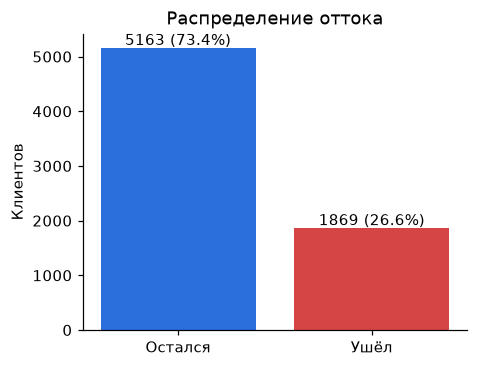

In [28]:
counts = df["Churn"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(["Остался", "Ушёл"], counts, color=[BLUE, RED])
for i, v in enumerate(counts):
    ax.text(i, v + 50, f"{v} ({v/len(df):.1%})", ha="center")
ax.set(title="Распределение оттока", ylabel="Клиентов")
plt.show()

Ушли 26,6% клиентов. Классы несбалансированы, поэтому:
- основные метрики: ROC-AUC и recall по ушедшим;
- в модели используются веса классов (`class_weight="balanced"`).

### 3.2 Срок контракта: тип договора

,клиентов,ушло,доля_оттока
Contract,,,
Помесячный,3875,1655,42.7%
1 год,1472,166,11.3%
2 года,1685,48,2.8%


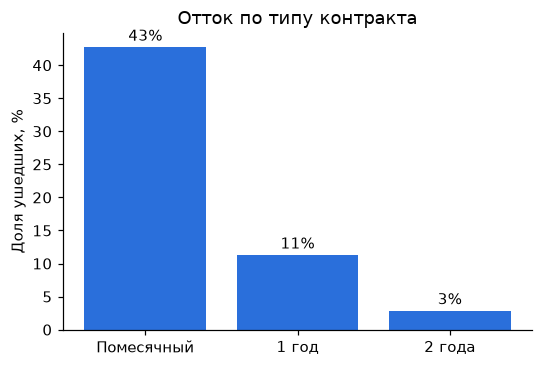

In [29]:
contract_order = ["Month-to-month", "One year", "Two year"]
contract_ru = {"Month-to-month": "Помесячный", "One year": "1 год", "Two year": "2 года"}
tab = (df.groupby("Contract")["Churn"].agg(клиентов="count", ушло="sum", доля_оттока="mean")
         .reindex(contract_order).rename(index=contract_ru))
display(tab.style.format({"доля_оттока": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(tab.index, tab["доля_оттока"] * 100, color=BLUE)
for i, v in enumerate(tab["доля_оттока"] * 100):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set(title="Отток по типу контракта", ylabel="Доля ушедших, %")
plt.show()

**Вывод.** Тип договора сильнее всего связан с оттоком. При помесячном договоре уходят 43% клиентов, при годовом 11%, при двухлетнем 3%. Помесячный договор позволяет уйти в любой момент без последствий.

### 3.3 Срок контракта: стаж клиента (tenure)

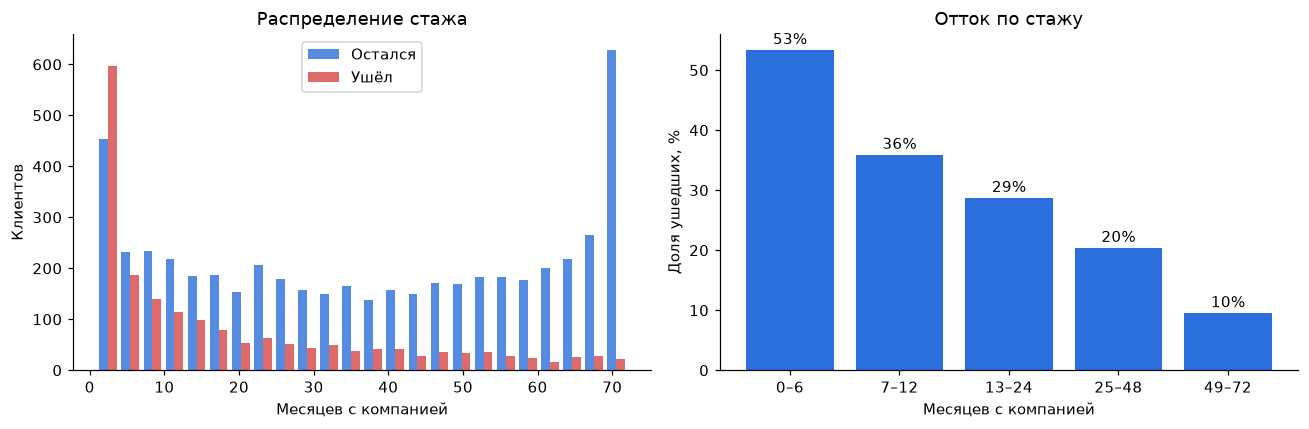

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist([df.loc[df.Churn == 0, "tenure"], df.loc[df.Churn == 1, "tenure"]],
             bins=24, label=["Остался", "Ушёл"], color=[BLUE, RED], alpha=0.8)
axes[0].set(title="Распределение стажа", xlabel="Месяцев с компанией", ylabel="Клиентов")
axes[0].legend()

bins = [0, 6, 12, 24, 48, 72]
labels = ["0–6", "7–12", "13–24", "25–48", "49–72"]
df["tenure_group"] = pd.cut(df["tenure"], bins, labels=labels)
by_t = df.groupby("tenure_group", observed=True)["Churn"].mean() * 100
axes[1].bar(labels, by_t, color=BLUE)
for i, v in enumerate(by_t):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center")
axes[1].set(title="Отток по стажу", xlabel="Месяцев с компанией", ylabel="Доля ушедших, %")
plt.tight_layout(); plt.show()

**Вывод.** Больше всего уходят новые клиенты: за первые полгода уходит 53%. С ростом стажа отток монотонно снижается и среди клиентов со стажем больше 4 лет составляет 10%. Значит, первый год сотрудничества является критическим периодом.

In [31]:
# Тип договора и стаж вместе
pivot = (df.pivot_table(index="tenure_group", columns="Contract", values="Churn",
                        aggfunc="mean", observed=True)[contract_order].rename(columns=contract_ru) * 100)
display(pivot.round(1).style.background_gradient(cmap="Reds", axis=None).format("{:.1f}%"))

Contract,Помесячный,1 год,2 года
tenure_group,,,
0–6,55.2%,10.5%,0.0%
7–12,42.0%,10.6%,0.0%
13–24,37.7%,8.1%,0.0%
25–48,32.9%,10.6%,2.2%
49–72,26.0%,12.9%,3.3%


Эффекты накладываются друг на друга. Новые клиенты на помесячном договоре уходят больше чем в половине случаев, а клиенты на двухлетнем договоре почти не уходят при любом стаже.

### 3.4 Частота взаимодействий: число подключённых услуг

В данных нет готового счётчика обращений, поэтому частоту взаимодействий клиента с компанией приближённо оценим числом подключённых услуг (`NumServices`, от 1 до 9). Каждая услуга это отдельная точка контакта: по ней выставляются счета, проходят обращения в поддержку и замены оборудования. В данных Setec вместо этого признака можно использовать число заявок в Service Desk и частоту встреч с заказчиком.

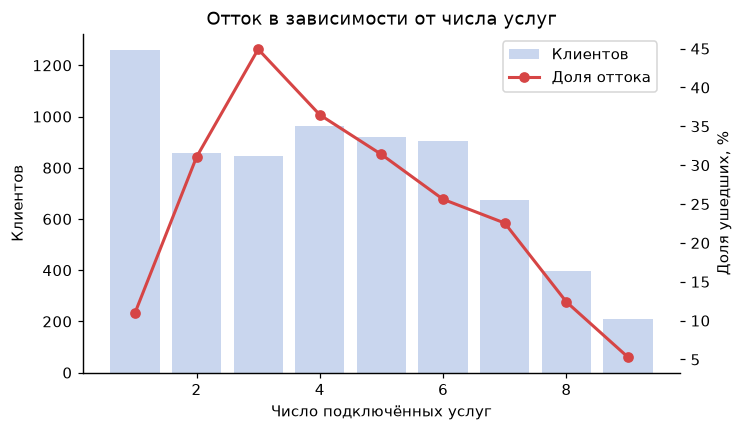

In [32]:
service_cols = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
                "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
no_vals = ("No", "No internet service", "No phone service")
df["NumServices"] = df[service_cols].apply(lambda r: sum(v not in no_vals for v in r), axis=1)

by_s = df.groupby("NumServices")["Churn"].agg(клиентов="count", доля_оттока="mean")
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.bar(by_s.index, by_s["клиентов"], color="#c9d6ee", label="Клиентов")
ax1.set(xlabel="Число подключённых услуг", ylabel="Клиентов")
ax2 = ax1.twinx()
ax2.plot(by_s.index, by_s["доля_оттока"] * 100, "o-", color=RED, lw=2, label="Доля оттока")
ax2.set_ylabel("Доля ушедших, %")
ax1.set_title("Отток в зависимости от числа услуг")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.show()

**Вывод.** Зависимость нелинейная. Клиенты с одной услугой (обычно только телефон) уходят редко (11%). Пик оттока приходится на 3–4 услуги (37–45%), дальше отток снижается и при 8–9 услугах составляет 5–12%. Чем глубже клиент интегрирован в экосистему компании, тем сложнее ему уйти. Для Setec это аргумент в пользу комплексных контрактов.

### 3.5 Конкретные услуги и способ оплаты

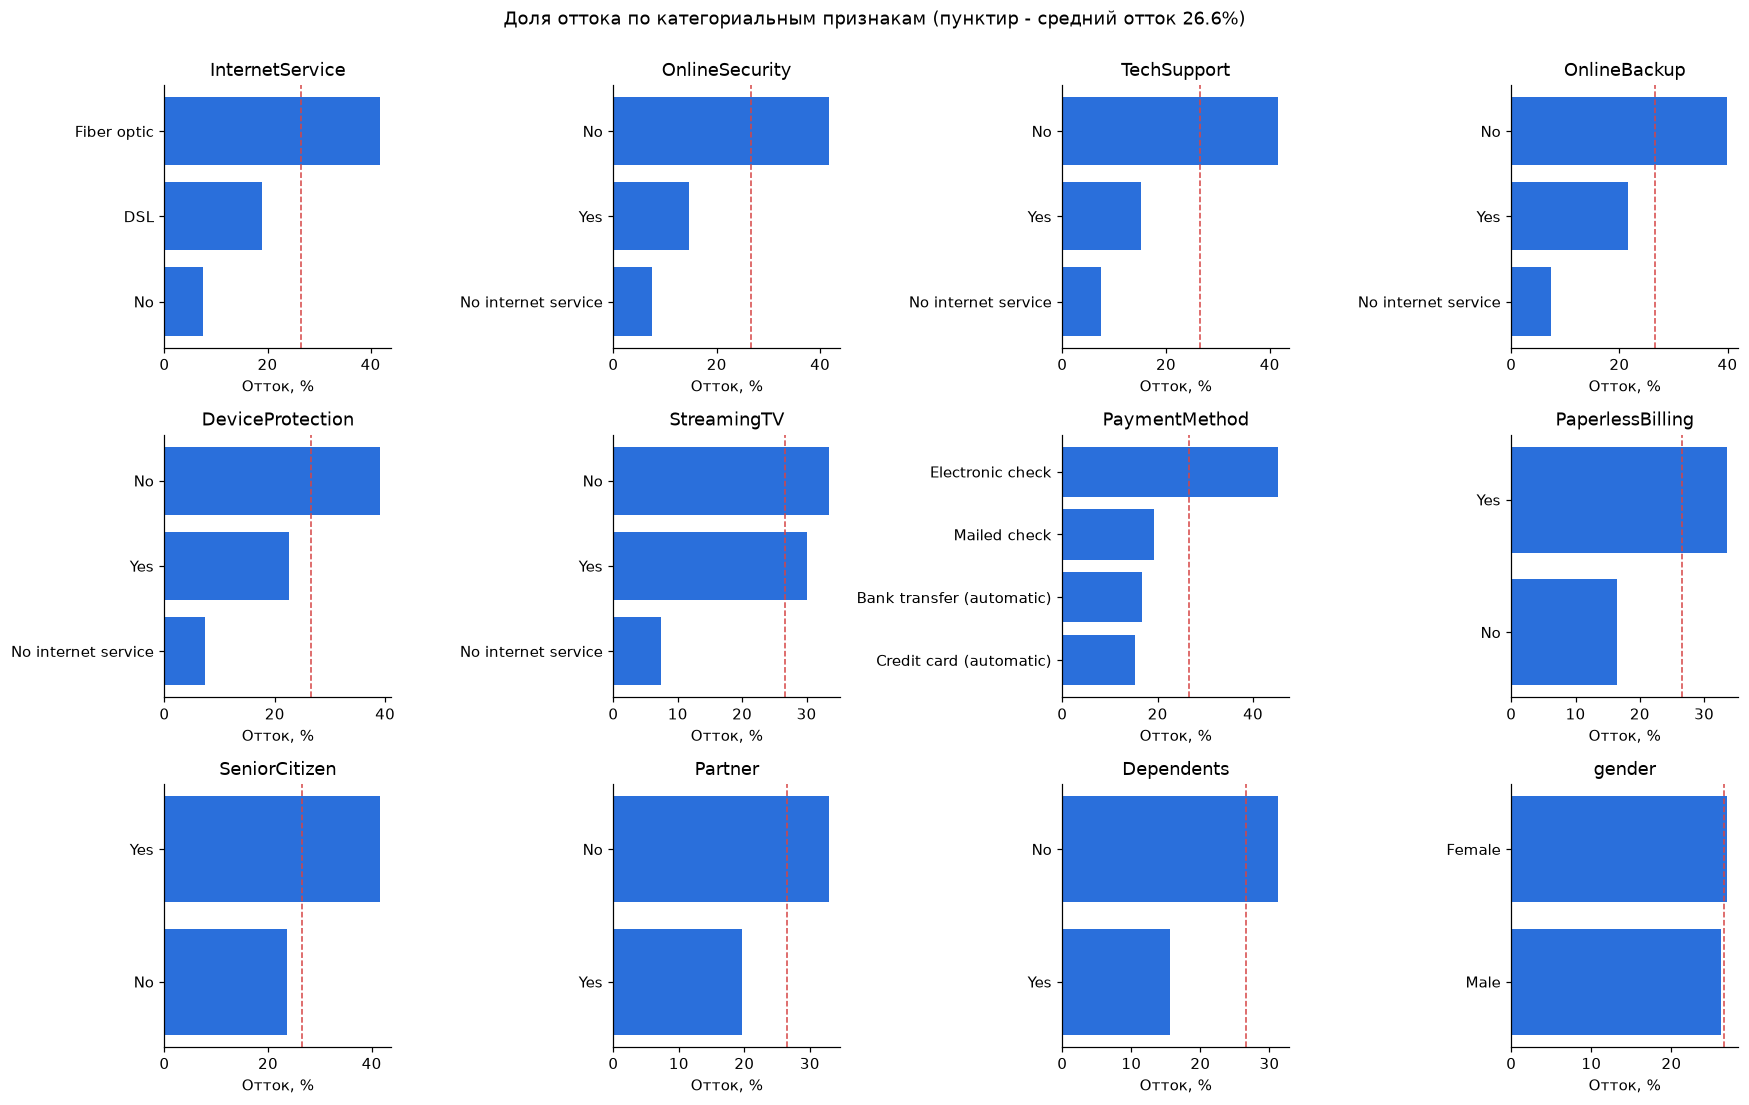

In [33]:
cat_cols = ["InternetService", "OnlineSecurity", "TechSupport", "OnlineBackup",
            "DeviceProtection", "StreamingTV", "PaymentMethod", "PaperlessBilling",
            "SeniorCitizen", "Partner", "Dependents", "gender"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, cat_cols):
    r = df.groupby(col)["Churn"].mean().sort_values() * 100
    ax.barh(r.index.astype(str), r, color=BLUE)
    ax.axvline(df.Churn.mean() * 100, color=RED, ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("Отток, %")
plt.suptitle("Доля оттока по категориальным признакам (пунктир - средний отток 26.6%)", y=1.0)
plt.tight_layout(); plt.show()

**Наблюдения**
- **Оптоволоконный интернет** даёт отток 42%: это дорогая услуга, и, вероятно, ею недовольны по цене или качеству.
- Клиенты **без техподдержки и без защиты (OnlineSecurity)** уходят в 2,5–3 раза чаще. Сервисное сопровождение удерживает клиента, и для Setec это особенно показательно.
- Оплата **электронным чеком** даёт отток 45%: ручная оплата каждый месяц, без автоплатежа и без привязки к клиенту.
- Пол на отток не влияет.

### 3.6 Платежи

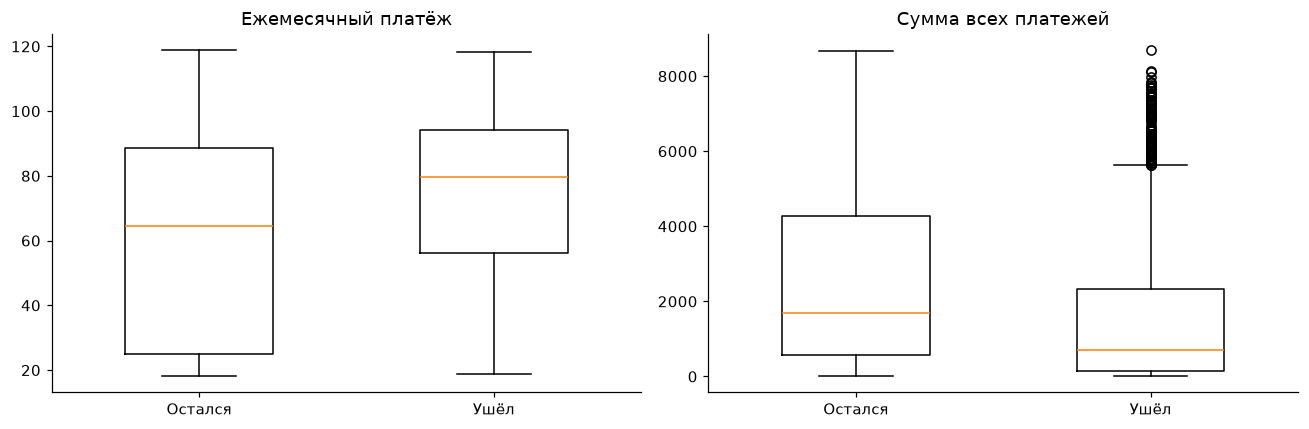

,MonthlyCharges,TotalCharges,tenure
Churn,,,
Остался,64.4,1683.6,38.0
Ушёл,79.6,703.6,10.0


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "MonthlyCharges", "Ежемесячный платёж"),
                       (axes[1], "TotalCharges", "Сумма всех платежей")]:
    ax.boxplot([df.loc[df.Churn == 0, col], df.loc[df.Churn == 1, col]],
               tick_labels=["Остался", "Ушёл"], widths=0.5)
    ax.set_title(title)
plt.tight_layout(); plt.show()
display(df.groupby("Churn")[["MonthlyCharges", "TotalCharges", "tenure"]].median()
          .rename(index={0: "Остался", 1: "Ушёл"}).round(1))

Ушедшие клиенты платят в месяц больше (медиана 80 против 64), но в сумме за всё время меньше, потому что уходят рано.

### 3.7 Корреляции числовых признаков

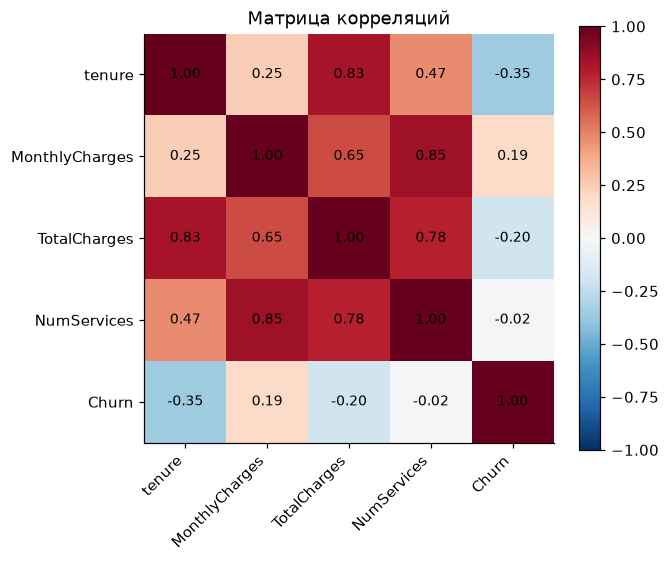

In [35]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "NumServices", "Churn"]]
corr = num.corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im); ax.set_title("Матрица корреляций"); plt.show()

`TotalCharges` сильно коррелирует со стажем (0,83) и с числом услуг: по сути это произведение стажа на ежемесячный платёж. Чтобы избежать мультиколлинеарности, из-за которой коэффициенты логистической регрессии становятся неустойчивыми и плохо интерпретируются, `TotalCharges` в модель не включается.

## 4. Статистическая проверка связи признаков с оттоком

In [36]:
rows = []
for col in ["Contract", "InternetService", "TechSupport", "OnlineSecurity", "PaymentMethod",
            "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "gender"]:
    ct = pd.crosstab(df[col], df["Churn"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))
    rows.append([col, "χ² (категориальный)", chi2, p, cramers_v])
# число услуг проверяем двумя тестами: связь с оттоком немонотонная (пик на 3–4 услугах)
ct = pd.crosstab(df["NumServices"], df["Churn"])
chi2, p, _, _ = stats.chi2_contingency(ct)
rows.append(["NumServices", "χ² (по группам 1…9)", chi2, p, np.sqrt(chi2 / len(df))])
for col in ["tenure", "MonthlyCharges", "NumServices"]:
    u, p = stats.mannwhitneyu(df.loc[df.Churn == 1, col], df.loc[df.Churn == 0, col])
    r = 1 - 2 * u / (df.Churn.sum() * (len(df) - df.Churn.sum()))  # ранговая бисериальная
    rows.append([col, "Манн–Уитни (числовой)", u, p, abs(r)])
tests = (pd.DataFrame(rows, columns=["Признак", "Тест", "Статистика", "p-value", "Сила связи"])
           .sort_values("Сила связи", ascending=False))
display(tests.style.format({"Статистика": "{:.0f}", "p-value": "{:.1e}", "Сила связи": "{:.3f}"}))

,Признак,Тест,Статистика,p-value,Сила связи
12,tenure,Манн–Уитни (числовой),2494979,6.0e-211,0.483
0,Contract,χ² (категориальный),1180,7.3e-257,0.410
3,OnlineSecurity,χ² (категориальный),847,1.4e-184,0.347
2,TechSupport,χ² (категориальный),825,7.4e-180,0.343
1,InternetService,χ² (категориальный),729,5.8e-159,0.322
4,PaymentMethod,χ² (категориальный),645,1.4e-139,0.303
11,NumServices,χ² (по группам 1…9),467,1.1e-95,0.258
13,MonthlyCharges,Манн–Уитни (числовой),5986148,8.5e-54,0.241
5,PaperlessBilling,χ² (категориальный),257,8.2e-58,0.191
8,Dependents,χ² (категориальный),186,2.0e-42,0.163


Сила связи: V Крамера для категориальных признаков и ранговый бисериальный коэффициент для числовых.

**Выводы**
- Почти все признаки значимо связаны с оттоком (p < 0,05). Сильнее всего связаны **стаж** и **тип договора**, то есть оба показателя срока контракта.
- Пол (`gender`, p ≈ 0,49) и наличие телефона (`PhoneService`) значимо не связаны с оттоком.
- По числу услуг (`NumServices`) тест Манна–Уитни не находит различий (p ≈ 0,67), а χ² по группам находит сильную связь. Противоречия нет: связь немонотонная (рост до 3–4 услуг, затем спад, см. п. 3.4), а тест Манна–Уитни улавливает только сдвиг «больше/меньше». Поэтому в модели число услуг полезно вместе с конкретными услугами, а не само по себе как линейный признак.

## 5. Построение модели логистической регрессии

### 5.1 Подготовка признаков и разбиение

In [37]:
numeric = ["tenure", "MonthlyCharges", "NumServices"]
categorical = ["Contract", "PaymentMethod", "PaperlessBilling", "InternetService",
               "OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection",
               "StreamingTV", "StreamingMovies", "MultipleLines", "PhoneService",
               "SeniorCitizen", "Partner", "Dependents", "gender"]
X, y = df[numeric + categorical], df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Обучающая выборка: {len(X_train)}, тестовая: {len(X_test)}")
print(f"Доля оттока: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

Обучающая выборка: 5625, тестовая: 1407
Доля оттока: train 26.6%, test 26.6%


- Выборка делится 80/20 со стратификацией.
- Числовые признаки стандартизуются. Это нужно, чтобы их коэффициенты можно было сравнивать между собой.
- Категориальные признаки кодируются one-hot.

### 5.2 Модель

Логистическая регрессия оценивает вероятность ухода клиента:

$$P(\text{отток}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

Коэффициент $\beta_i > 0$ означает, что признак повышает риск ухода, $\beta_i < 0$ — что снижает. Величина $e^{\beta_i}$ — **отношение шансов**: во сколько раз меняются шансы ухода при изменении признака.

In [45]:
prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
])
model = Pipeline([
    ("prep", prep),
    ("logreg", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print("ROC-AUC по фолдам:", cv_auc.round(3))
print(f"Среднее: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

model.fit(X_train, y_train)

ROC-AUC по фолдам: [0.848 0.84  0.835 0.848 0.85 ]
Среднее: 0.844 ± 0.006


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['tenure','MonthlyCharges','NumServices',...,'Partner','Dependents', 'gender']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all 

Качество на пяти фолдах почти одинаковое, разброс маленький. Значит, модель устойчива и не переобучена.

### 5.3 Сравнение с базовыми моделями

In [39]:
def auc_of(features):
    num_f = [c for c in features if c in numeric]
    cat_f = [c for c in features if c in categorical]
    p = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num_f),
                                              ("cat", OneHotEncoder(drop="first"), cat_f)])),
                  ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    return cross_val_score(p, X_train[features], y_train, cv=cv, scoring="roc_auc").mean()

dummy = cross_val_score(DummyClassifier(), X_train, y_train, cv=cv, scoring="roc_auc").mean()
compare = pd.DataFrame({
    "Модель": ["Случайное угадывание",
               "Только срок контракта (Contract + tenure)",
               "Срок контракта + частота взаимодействий (+ NumServices)",
               "Все признаки"],
    "ROC-AUC (CV)": [dummy, auc_of(["Contract", "tenure"]),
                     auc_of(["Contract", "tenure", "NumServices"]), cv_auc.mean()],
})
display(compare.style.format({"ROC-AUC (CV)": "{:.3f}"}).hide(axis="index"))

Модель,ROC-AUC (CV)
Случайное угадывание,0.500
Только срок контракта (Contract + tenure),0.788
Срок контракта + частота взаимодействий (+ NumServices),0.803
Все признаки,0.844


**Вывод.** Один только срок контракта даёт ROC-AUC ≈ 0,79, добавление числа услуг поднимает его до ≈ 0,80, а все признаки до ≈ 0,84. Признаки из задания дают основную часть качества, а состав конкретных услуг и способ оплаты добавляют ещё несколько пунктов.

## 6. Оценка качества на тестовой выборке

ROC-AUC на тесте: 0.833

              precision    recall  f1-score   support

     Остался      0.900     0.708     0.792      1033
        Ушёл      0.492     0.783     0.605       374

    accuracy                          0.728      1407
   macro avg      0.696     0.746     0.699      1407
weighted avg      0.792     0.728     0.743      1407



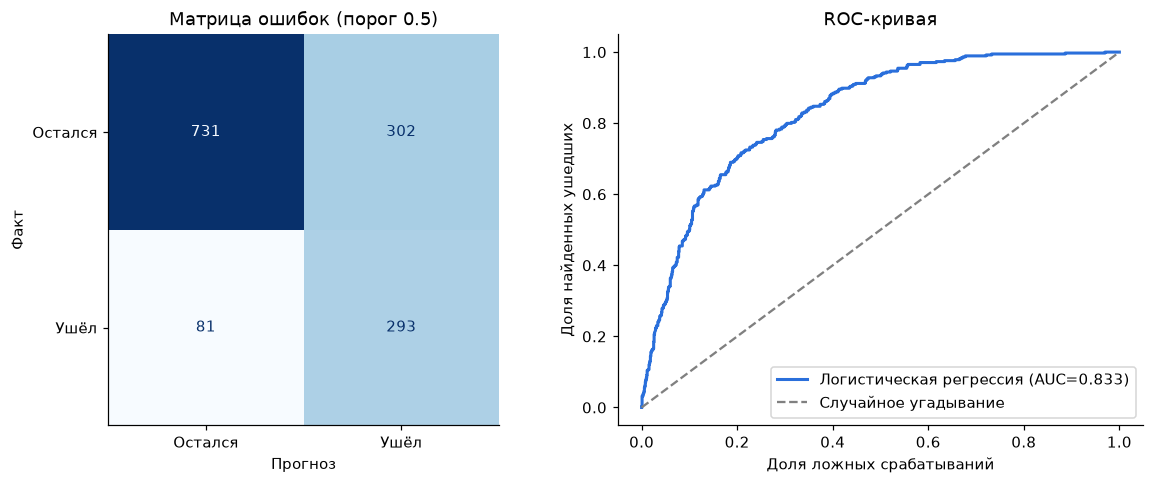

In [40]:
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print(f"ROC-AUC на тесте: {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, pred, target_names=["Остался", "Ушёл"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Остался", "Ушёл"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set(title="Матрица ошибок (порог 0.5)", xlabel="Прогноз", ylabel="Факт")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color=BLUE, lw=2, label=f"Логистическая регрессия (AUC={roc_auc_score(y_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Случайное угадывание")
axes[1].set(title="ROC-кривая", xlabel="Доля ложных срабатываний", ylabel="Доля найденных ушедших")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Как читать результат**
- **Recall по ушедшим ≈ 0,78**: модель находит 78% клиентов, которые действительно уйдут.
- **Precision ≈ 0,49**: примерно половина клиентов, отмеченных как группа риска, действительно уходит.
- **ROC-AUC ≈ 0,83**: хорошее качество разделения классов. 0,5 соответствует случайному угадыванию, 1,0 — идеальному прогнозу.

Для задачи удержания пропустить уходящего клиента обычно дороже, чем лишний раз с ним связаться. Поэтому приоритет отдаётся высокой полноте.

### 6.1 Выбор порога классификации

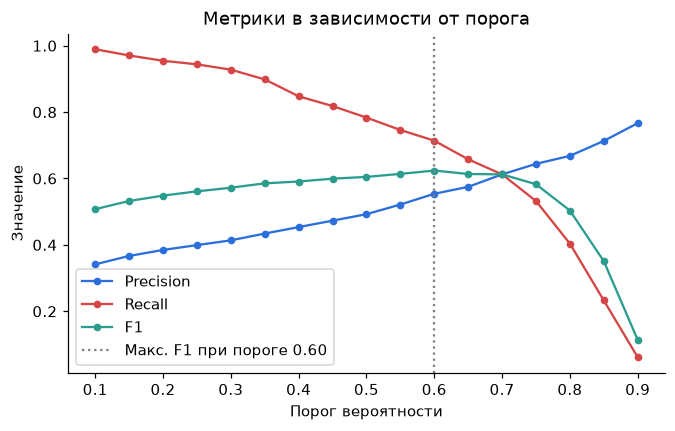

Порог,Precision,Recall,F1,Клиентов в группе риска
0.10,0.341,0.989,0.508,1084
0.20,0.385,0.955,0.548,928
0.30,0.414,0.928,0.572,839
0.40,0.454,0.848,0.591,699
0.50,0.492,0.783,0.605,595
0.60,0.554,0.714,0.624,482
0.70,0.612,0.612,0.612,374
0.80,0.668,0.404,0.503,226
0.90,0.767,0.061,0.114,30


In [41]:
thr = np.arange(0.1, 0.91, 0.05)
rows = [[t, precision_score(y_test, proba >= t), recall_score(y_test, proba >= t),
         f1_score(y_test, proba >= t), (proba >= t).sum()] for t in thr]
th = pd.DataFrame(rows, columns=["Порог", "Precision", "Recall", "F1", "Клиентов в группе риска"])

fig, ax = plt.subplots(figsize=(7, 4))
for col, c in [("Precision", BLUE), ("Recall", RED), ("F1", GREEN)]:
    ax.plot(th["Порог"], th[col], "o-", label=col, color=c, ms=4)
best = th.loc[th.F1.idxmax()]
ax.axvline(best["Порог"], color="grey", ls=":", label=f"Макс. F1 при пороге {best['Порог']:.2f}")
ax.set(title="Метрики в зависимости от порога", xlabel="Порог вероятности", ylabel="Значение")
ax.legend(); plt.show()
display(th.iloc[::2].style.format({"Порог": "{:.2f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}).hide(axis="index"))

Порог задаёт компромисс между полнотой и точностью, и выбирают его исходя из бюджета на удержание:
- если удержание дешёвое (звонок, письмо), подходит низкий порог: охватываем больше клиентов риска;
- если удержание дорогое (скидка, персональный менеджер), подходит высокий порог: работаем только с теми, кто почти наверняка уйдёт.

## 7. Интерпретация коэффициентов

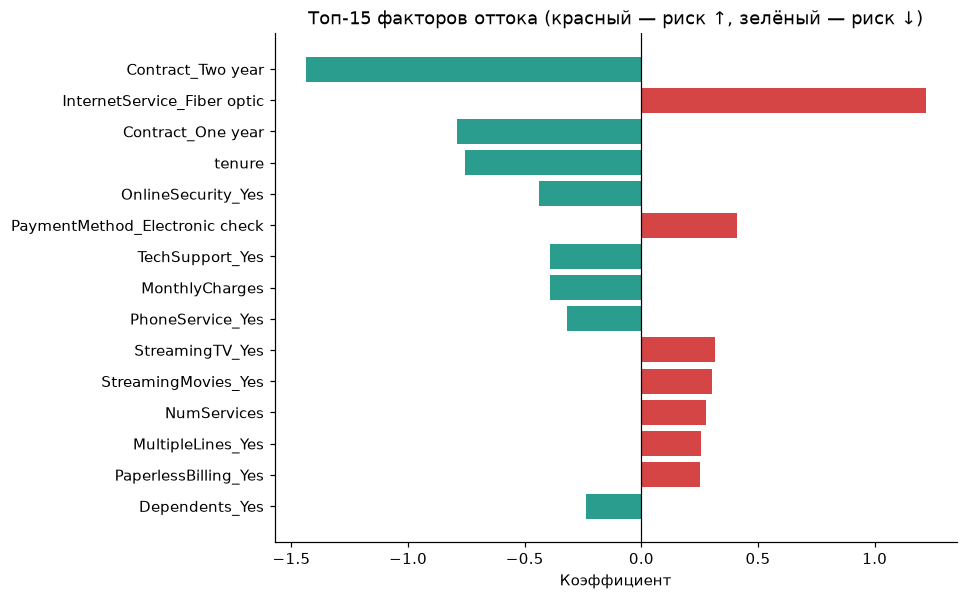

,Признак,Коэффициент,Отношение шансов
0,Contract_Two year,-1.439,0.24
1,InternetService_Fiber optic,+1.219,3.38
2,Contract_One year,-0.789,0.45
3,tenure,-0.758,0.47
4,OnlineSecurity_Yes,-0.437,0.65
5,PaymentMethod_Electronic check,+0.411,1.51
6,TechSupport_Yes,-0.391,0.68
7,MonthlyCharges,-0.390,0.68
8,PhoneService_Yes,-0.319,0.73
9,StreamingTV_Yes,+0.316,1.37


In [42]:
names = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]
coefs = model.named_steps["logreg"].coef_[0]
coef_df = (pd.DataFrame({"Признак": names, "Коэффициент": coefs, "Отношение шансов": np.exp(coefs)})
             .sort_values("Коэффициент", key=abs, ascending=False).reset_index(drop=True))

top = coef_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["Признак"], top["Коэффициент"], color=[RED if c > 0 else GREEN for c in top["Коэффициент"]])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Топ-15 факторов оттока (красный — риск ↑, зелёный — риск ↓)", xlabel="Коэффициент")
plt.show()
display(coef_df.style.format({"Коэффициент": "{:+.3f}", "Отношение шансов": "{:.2f}"})
        .background_gradient(subset=["Коэффициент"], cmap="RdYlGn_r", vmin=-1.5, vmax=1.5))

**Интерпретация** (отношение шансов: < 1 — риск ниже, > 1 — риск выше)

| Фактор | Эффект |
|---|---|
| Договор на 2 года (относительно помесячного) | шансы ухода ниже в ~4 раза (ОШ ≈ 0,24) |
| Договор на 1 год | шансы ухода ниже в ~2 раза (ОШ ≈ 0,45) |
| Стаж (+1 стандартное отклонение ≈ 2 года) | шансы ухода ниже в ~2 раза (ОШ ≈ 0,47) |
| Оптоволоконный интернет | шансы ухода выше в ~3,4 раза |
| Оплата электронным чеком | шансы ухода выше в ~1,5 раза |
| Подключены техподдержка или защита | шансы ухода ниже на ~1/3 |

Оба фактора срока контракта входят в число самых сильных предикторов, что подтверждает гипотезу задания.

**Примичание** У `MonthlyCharges` отрицательный коэффициент, хотя в EDA ушедшие клиенты платят больше. Причина в том, что платёж почти полностью определяется набором услуг, которые тоже есть в модели. Коэффициент показывает эффект платежа при фиксированном наборе услуг, поэтому отдельно его интерпретировать нельзя. Это проявление мультиколлинеарности.

## 8. Сегментация клиентов по риску

,Клиентов,Доля_клиентов,Фактический_отток,Ушло,Доля_всех_ушедших
Риск,,,,,
Низкий,568,40.4%,4.8%,27,7.2%
Средний,357,25.4%,22.4%,80,21.4%
Высокий,482,34.3%,55.4%,267,71.4%


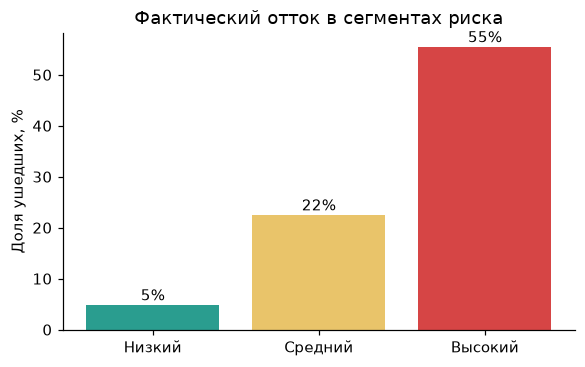

In [43]:
scored = X_test.copy()
scored["customerID"] = df.loc[X_test.index, "customerID"]
scored["Вероятность оттока"] = proba
scored["Факт"] = y_test.values
scored["Риск"] = pd.cut(proba, [0, 0.3, 0.6, 1.0], labels=["Низкий", "Средний", "Высокий"], include_lowest=True)

seg = scored.groupby("Риск", observed=True).agg(
    Клиентов=("customerID", "count"),
    Доля_клиентов=("customerID", lambda s: len(s) / len(scored)),
    Фактический_отток=("Факт", "mean"),
    Ушло=("Факт", "sum"))
seg["Доля_всех_ушедших"] = seg["Ушло"] / seg["Ушло"].sum()
display(seg.style.format({"Доля_клиентов": "{:.1%}", "Фактический_отток": "{:.1%}", "Доля_всех_ушедших": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(seg.index.astype(str), seg["Фактический_отток"] * 100, color=[GREEN, "#e9c46a", RED])
for i, v in enumerate(seg["Фактический_отток"] * 100):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set(title="Фактический отток в сегментах риска", ylabel="Доля ушедших, %")
plt.show()

In [44]:
# Портрет клиента из группы высокого риска в сравнении с низким
profile = scored.groupby("Риск", observed=True).agg(
    Стаж_мес=("tenure", "median"), Платёж=("MonthlyCharges", "median"), Услуг=("NumServices", "median"),
    Помесячный_договор=("Contract", lambda s: (s == "Month-to-month").mean()),
    Без_техподдержки=("TechSupport", lambda s: (s == "No").mean()),
    Оптоволокно=("InternetService", lambda s: (s == "Fiber optic").mean()))
display(profile.style.format({c: "{:.0%}" for c in ["Помесячный_договор", "Без_техподдержки", "Оптоволокно"]}))

print("Топ-10 клиентов с наибольшим риском ухода:")
display(scored.sort_values("Вероятность оттока", ascending=False)
        [["customerID", "Вероятность оттока", "Contract", "tenure", "NumServices", "MonthlyCharges", "Факт"]]
        .head(10).style.format({"Вероятность оттока": "{:.1%}"}).hide(axis="index"))

,Стаж_мес,Платёж,Услуг,Помесячный_договор,Без_техподдержки,Оптоволокно
Риск,,,,,,
Низкий,54.500000,54.475000,4.000000,10%,17%,17%
Средний,22.000000,55.900000,4.000000,73%,50%,38%
Высокий,9.000000,79.650000,4.000000,98%,90%,79%


Топ-10 клиентов с наибольшим риском ухода:


customerID,Вероятность оттока,Contract,tenure,NumServices,MonthlyCharges,Факт
5178-LMXOP,94.5%,Month-to-month,1,5,95.100000,1
5150-ITWWB,94.4%,Month-to-month,3,5,94.850000,0
6861-XWTWQ,93.8%,Month-to-month,7,6,99.250000,1
6023-YEBUP,93.4%,Month-to-month,3,6,100.950000,1
9057-SIHCH,93.1%,Month-to-month,3,5,96.600000,1
1069-XAIEM,93.0%,Month-to-month,1,4,85.050000,1
2865-TCHJW,92.8%,Month-to-month,4,5,89.200000,1
4750-ZRXIU,92.4%,Month-to-month,4,4,84.600000,1
6521-YYTYI,92.2%,Month-to-month,1,5,93.300000,1
4078-SAYYN,91.8%,Month-to-month,11,6,100.750000,1


Сегменты хорошо разделяют клиентов. В группе высокого риска уходит больше половины клиентов, и на неё приходится основная доля всех ушедших. В группе низкого риска отток около 5%.

**Типичный клиент высокого риска:** помесячный договор, стаж до года, оптоволокно, нет техподдержки.

## 9. Выводы и рекомендации

### Результаты
1. Построена модель логистической регрессии для прогноза оттока: **ROC-AUC ≈ 0,83–0,84**, найдено **~78%** уходящих клиентов.
2. Гипотеза задания подтвердилась:
   - **срок контракта** - главный фактор. Долгосрочный договор снижает шансы ухода в 2–4 раза, отток наиболее высок в первые 6–12 месяцев;
   - **частота взаимодействий** (число услуг). Клиенты, глубоко интегрированные в сервисы компании (8–9 услуг), почти не уходят.
3. Сервисная поддержка (техподдержка, защита) заметно снижает отток.
4. Модель разбивает клиентов на сегменты риска, с которыми можно работать по-разному.

### Рекомендации по удержанию (в переносе на Setec)
| Вывод модели | Мера для Setec |
|---|---|
| Долгосрочный договор снижает отток в 2–4 раза | Предлагать многолетние договоры обслуживания и SLA со скидкой за срок; заранее инициировать продление |
| Риск максимален в первый год | Программа сопровождения новых заказчиков: закреплённый менеджер, регулярные встречи и отчёты по SLA в первые 6–12 месяцев |
| Больше услуг - ниже отток | Кросс-продажи: техобслуживание + мониторинг + ИБ-сервисы; комплексный ИТ-аутсорсинг вместо разовых работ |
| Техподдержка и защита удерживают клиентов | Включать базовую поддержку и мониторинг в каждый проект |
| Сегменты риска | Ежемесячно рассчитывать вероятность ухода по CRM; заказчикам с высоким риском — звонок руководителя направления и аудит удовлетворённости |

### Ограничения
- Использованы **открытые данные** телеком-компании, а не клиенты Setec. Выводы показывают методику; числовые оценки нужно пересчитать на реальных данных.
- Частота взаимодействий оценена **косвенно** (через число услуг). В данных Setec лучше использовать число заявок, инцидентов и встреч с заказчиком.
- Логистическая регрессия предполагает линейную связь признаков с логарифмом шансов. Нелинейность (например, по числу услуг) она учитывает лишь частично.